# Fed rates: one line plot per value column

Reads `base_data_fed_rates` from PostgreSQL (connection settings come from the project `.env`) and plots each value column against `observation_date`.

In [3]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import psycopg2
from dotenv import load_dotenv

# Find the project .env by walking up from the notebook's folder.
env_path = next(
    (p / ".env" for p in [Path.cwd(), *Path.cwd().parents] if (p / ".env").exists()),
    None,
)
if env_path is None:
    raise FileNotFoundError("No .env file found in this folder or any parent.")
load_dotenv(env_path)

TABLE = "base_data_fed_rates"
DATE_COLUMN = "observation_date"

In [4]:
conn = psycopg2.connect(
    dbname=os.environ["POSTGRES_DB"],
    user=os.environ["POSTGRES_USER"],
    password=os.environ["POSTGRES_PASSWORD"],
    host=os.environ["POSTGRES_HOST"],
    port=int(os.environ["POSTGRES_PORT"]),
)
try:
    with conn.cursor() as cur:
        cur.execute(f'SELECT * FROM "{TABLE}" ORDER BY "{DATE_COLUMN}"')
        columns = [desc[0] for desc in cur.description]
        df = pd.DataFrame(cur.fetchall(), columns=columns)
finally:
    conn.close()

df[DATE_COLUMN] = pd.to_datetime(df[DATE_COLUMN])
value_columns = [c for c in df.columns if c != DATE_COLUMN]
for c in value_columns:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df.head()

,observation_date,effective_rate,four_year_installment
0,2023-01-01,4.33,7.46
1,2023-02-01,4.57,NaN
2,2023-03-01,4.65,NaN
3,2023-04-01,4.83,7.59
4,2023-05-01,5.06,NaN


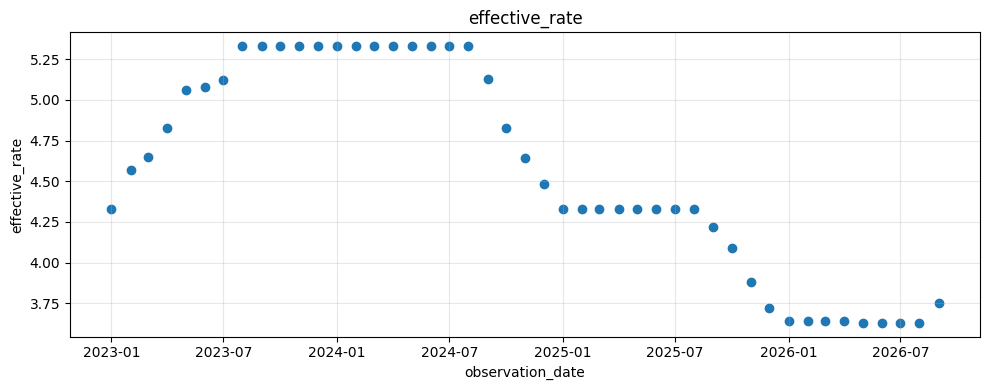

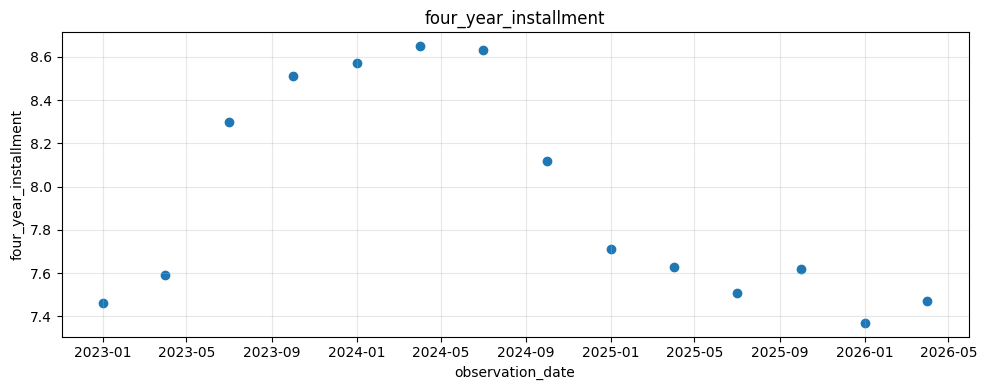

In [10]:
# One figure per value column; dates on x, values on y.
for column in value_columns:
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.scatter(df[DATE_COLUMN], df[column])
    ax.set_title(column)
    ax.set_xlabel(DATE_COLUMN)
    ax.set_ylabel(column)
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()